# Hackathon – Dataset C (COVID vaccine) · Notebook 01 of 09
## Problem framing and the task-specific cost metric

**Module:** 7PAM2002 – University of Hertfordshire · **GitHub:** `<add link>` · **Colab:** `<add link>` · **Author of this notebook:** `<name>`

**Goal of the project:** predict which residents will accept a COVID vaccine and decide who to post a dose to so that the town's **total
cost (vaccines + hospitalisations)** is as small as possible.

<details><summary><b>The nine notebooks (run them in this order)</b></summary>

| # | Notebook | Content |
|---|---|---|
| 01 | `01_Problem_Framing_and_Cost_Metric.ipynb` | Problem framing and the task-specific cost metric |
| 02 | `02_EDA_Data_Quality.ipynb` | EDA part 1 – overview, target, missing values, data quality, train/test shift |
| 03 | `03_EDA_Feature_Relationships.ipynb` | EDA part 2 – distributions, associations, interactions, cost drivers |
| 04 | `04_Preprocessing.ipynb` | Pre-processing – cleaning, feature engineering, comparing four options |
| 05 | `05_Model_Tuning.ipynb` | Modelling – six model families and hyper-parameter tuning |
| 06 | `06_Cross_Validation_and_Decision_Strategy.ipynb` | Repeated cross-validation and turning probabilities into decisions |
| 07 | `07_Holdout_Evaluation_and_Robustness.ipynb` | Unseen hold-out evaluation, bootstrap uncertainty, robustness to assumptions |
| 08 | `08_Final_Selection_and_Submission.ipynb` | Final model selection and the five ranked submission files |
| 09 | `09_Explainable_AI_and_Conclusions.ipynb` | Explainable AI (SHAP, odds ratios, permutation importance) and conclusions |

Shared code (data loading, cost metric, cleaning, pipelines, models, evaluation helpers) lives in **`hackathon_utils.py`** so every notebook uses
exactly the same definitions. Results are passed from one notebook to the next through the **`artifacts/`** folder.
</details>


In [1]:
# ---- Set-up: run from the repository folder locally, or in Google Colab ----
import sys, os, subprocess, importlib, importlib.util
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/<your-organisation>/<your-repository>.git'   # <- set this once for Colab

if IN_COLAB and not Path('hackathon_utils.py').exists():
    subprocess.run(['git', 'clone', '-q', REPO_URL, 'repo'], check=True)   # get code, data and artifacts
    os.chdir('repo')

for pkg in ['xgboost', 'lightgbm', 'catboost', 'shap']:                    # CatBoost is not pre-installed on Colab
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hackathon_utils import *            # shared data, cost metric, pipelines, models and helpers
print('train:', train_raw.shape, '| test:', test_raw.shape, '| scikit-learn', sklearn.__version__)

train: (4756, 31) | test: (4749, 30) | scikit-learn 1.6.1


## 2. Understanding the task and deriving the evaluation metric

### 2.1 What exactly are we being scored on?
The brief says the goal is to **minimise the total money spent by the town**, made of (i) vaccine costs and (ii) hospitalisation costs.
The rules translate into a cost for every combination of *our decision* and *the person's true behaviour*:

* Everybody gets infected (100 % infection probability at winter parties).
* A vaccine is **posted to the person's home** if we predict they will accept it (ŷ = 1). If they refuse, the dose is ruined but has still been paid for.
* If we do **not** send a vaccine but the person wanted one (false negative), **the town must pay them the vaccine cost in cash** – and they stay unvaccinated.
* Hospitalisation cost = probability of hospitalisation × \$41 000. That probability depends on the person's characteristics and on whether they are vaccinated.

| Our decision ↓ / truth → | **Accepts** (y = 1) | **Refuses** (y = 0) |
|---|---|---|
| **Send vaccine** (ŷ = 1) | \$1 500 + 41 000·p·(1 − VE)  ← *vaccinated* | \$1 500 (wasted) + 41 000·p |
| **Don't send** (ŷ = 0) | \$1 500 (cash) + 41 000·p | \$0 + 41 000·p |

where **p** = probability that this *unvaccinated* person is hospitalised once infected, and **VE** = vaccine effectiveness against hospitalisation.

### 2.2 Consequences (why accuracy / F1 are the wrong targets)
* A false positive and a false negative cost the *same* \$1 500 directly, **but** only a true positive saves hospitalisation money
  (41 000 · p · VE). So the value of correctly reaching a willing person depends on *who* they are: an 18–34 year old with no
  chronic disease is "worth" a few hundred dollars of avoided hospital costs, a 65+ year old with chronic conditions is worth many thousands.
* Taking expectations with q = P(person accepts | features), sending is better than not sending when

$$\underbrace{1500 + q\,[41000\,p(1-VE)] + (1-q)\,41000\,p}_{\text{send}} \;<\; \underbrace{q\,1500 + 41000\,p}_{\text{don't send}}
\;\;\Longleftrightarrow\;\; q \;>\; t_i = \frac{1500}{1500 + 41000\cdot p_i\cdot VE}$$

So the **cost-optimal decision threshold is personal**: it is low (≈0.2) for high-risk residents and high (≈0.7) for low-risk residents.
A single threshold of 0.5 is never optimal. This is why we need (a) **well-calibrated probabilities** q and (b) a **hospitalisation-risk model** p.

### 2.3 Estimating the hospitalisation probability p (research)
The brief asks us to use generative AI to estimate p and to check robustness. We used an AI assistant grounded in published sources:

| Quantity | Value used | Source / reasoning |
|---|---|---|
| Infection-hospitalisation ratio by age (unvaccinated, pre-Omicron) | 18–49: 2.7 %, 50–64: 7.3 %, 65+: 17.9 % | CDC *Estimated COVID-19 Burden* Feb 2020–Sep 2021: hospitalisations ÷ infections per age group (e.g. 65+: 3.23 M / 18.0 M) |
| Split into the dataset's age bands | 18–34: 1.9 %, 35–44: 3.2 %, 45–54: 4.9 %, 55–64: 8.2 %, 65+: 17.9 % | log-linear interpolation that reproduces the CDC band averages |
| Chronic conditions (count) | relative risk 1 → 2.0, 2 → 3.0, 3+ → 4.0 | CDC/COVID-NET: ≥1 condition aRR 2.2–4.6; Atlanta cohort: >3 conditions aOR 4.2; French national cohort: 5+ HR ≈ 5.9 |
| Sex | male RR 1.33 | meta-analysis of 229 studies: men had RR 1.33 for hospitalisation once infected |
| Vaccine effectiveness against hospitalisation | 85 % | meta-analyses report ≈ 89 % (two doses); we shade down slightly for waning / variants |

Multipliers are **normalised within each age group** so that the town's average risk per age group still equals the CDC figure
(otherwise we would double-count the fact that older people have more chronic conditions).

**Robustness ("ask different AIs").** Different assistants / people give different numbers, so every result is also evaluated under four alternative
scenarios: age-only risk, one flat average risk for the whole town, a milder Omicron-era scenario (half the risk, VE 70 %), and a severe scenario
(1.5× risk, VE 95 %). The team can add the answers they obtained from Gemini/ChatGPT to `EXTRA_AI_SCENARIOS` below and every table updates automatically.

The scenario class below (from `hackathon_utils.py`) implements exactly the table and formula above:

In [3]:
show_source(HospScenario)

```python
@dataclass
class HospScenario:
    """Assumptions about P(hospitalised | infected, unvaccinated) and vaccine effectiveness (VE)."""
    name: str
    age_ihr: dict                 # infection-hospitalisation ratio per age group
    cond_rr: dict = None          # relative risk by number of chronic conditions (None = ignore)
    male_rr: float = 1.0          # relative risk for men
    ve: float = 0.85              # vaccine effectiveness against hospitalisation
    scale: float = 1.0            # multiply all risks (e.g. milder variant)
    flat: bool = False            # True = give everybody the town-average risk

    def _multiplier(self, df):
        mult = np.ones(len(df))
        if self.cond_rr:
            n = df['number_chronic_med_conditions'].clip(upper=max(self.cond_rr))
            mult *= n.map(self.cond_rr).to_numpy()
        mult *= np.where(df['sex'].eq('Male'), self.male_rr, 1.0)
        return mult

    def fit(self, town):
        """Normalise multipliers so each age group's mean risk equals the published IHR for that age."""
        self.norm_ = pd.Series(self._multiplier(town)).groupby(town['age_group'].to_numpy()).mean().to_dict()
        self.town_mean_ = self._individual(town).mean()
        return self

    def _individual(self, df):
        base = df['age_group'].map(self.age_ihr).to_numpy(dtype=float) * self.scale
        norm = df['age_group'].map(self.norm_).to_numpy(dtype=float)
        return np.clip(base * self._multiplier(df) / norm, 0, 0.95)

    def p_unvacc(self, df):
        """P(hospitalised | infected, NOT vaccinated) for every row of df."""
        return np.full(len(df), self.town_mean_) if self.flat else self._individual(df)

    def personal_threshold(self, df):
        """Acceptance probability above which posting a dose lowers the expected cost."""
        return VACCINE_COST / (VACCINE_COST + HOSP_COST * self.ve * self.p_unvacc(df))

    def global_threshold(self):
        """Optimal single threshold if everybody had the town-average risk."""
        return VACCINE_COST / (VACCINE_COST + HOSP_COST * self.ve * self.town_mean_)

    def cost(self, y, send, df):
        """Total town cost ($) of decisions `send` for people whose true behaviour is `y`."""
        y, send = np.asarray(y).astype(bool), np.asarray(send).astype(bool)
        p = self.p_unvacc(df)
        vaccine_money = VACCINE_COST * (send | y)                 # dose posted (used or wasted) or cash paid
        hosp_money = HOSP_COST * p * np.where(send & y, 1 - self.ve, 1.0)
        return float(vaccine_money.sum() + hosp_money.sum())

    def breakdown(self, y, send, df):
        """Cost split into its parts (doses used / wasted, cash payouts, hospitalisations)."""
        y, send = np.asarray(y).astype(bool), np.asarray(send).astype(bool)
        p = self.p_unvacc(df)
        exp_hosp = (p * np.where(send & y, 1 - self.ve, 1.0)).sum()
        return {'doses used (TP)': int((send & y).sum()), 'doses wasted (FP)': int((send & ~y).sum()),
                'cash payouts (FN)': int((~send & y).sum()), 'expected hospitalisations': round(exp_hosp, 1),
                'vaccine-related $': VACCINE_COST * int((send | y).sum()), 'hospital $': round(HOSP_COST * exp_hosp),
                'TOTAL $': round(self.cost(y, send, df))}

```

In [2]:
print('Research-based infection-hospitalisation ratios by age:', AGE_IHR)
print('Relative risk by number of chronic conditions:', COND_RR, '| men: 1.33 | vaccine effectiveness:', MAIN.ve)
print(f'Average unvaccinated hospitalisation risk in the town: {MAIN.town_mean_:.2%}')
print(f'Optimal single threshold (flat risk):                  {MAIN.global_threshold():.3f}')
pd.DataFrame({s.name: {'mean p': round(s.town_mean_, 4), 've': s.ve, 'global threshold': round(s.global_threshold(), 3)}
              for s in SCENARIOS}).T

Research-based infection-hospitalisation ratios by age: {'18 - 34 Years': 0.019, '35 - 44 Years': 0.032, '45 - 54 Years': 0.049, '55 - 64 Years': 0.082, '65+ Years': 0.179}
Relative risk by number of chronic conditions: {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0} | men: 1.33 | vaccine effectiveness: 0.85
Average unvaccinated hospitalisation risk in the town: 8.20%
Optimal single threshold (flat risk):                  0.344


,mean p,ve,global threshold
A: age+conditions+sex (main),0.082,0.85,0.344
B: age only,0.082,0.85,0.344
C: flat town average,0.082,0.85,0.344
D: mild (Omicron-like),0.041,0.70,0.560
"E: severe, high VE",0.123,0.95,0.239


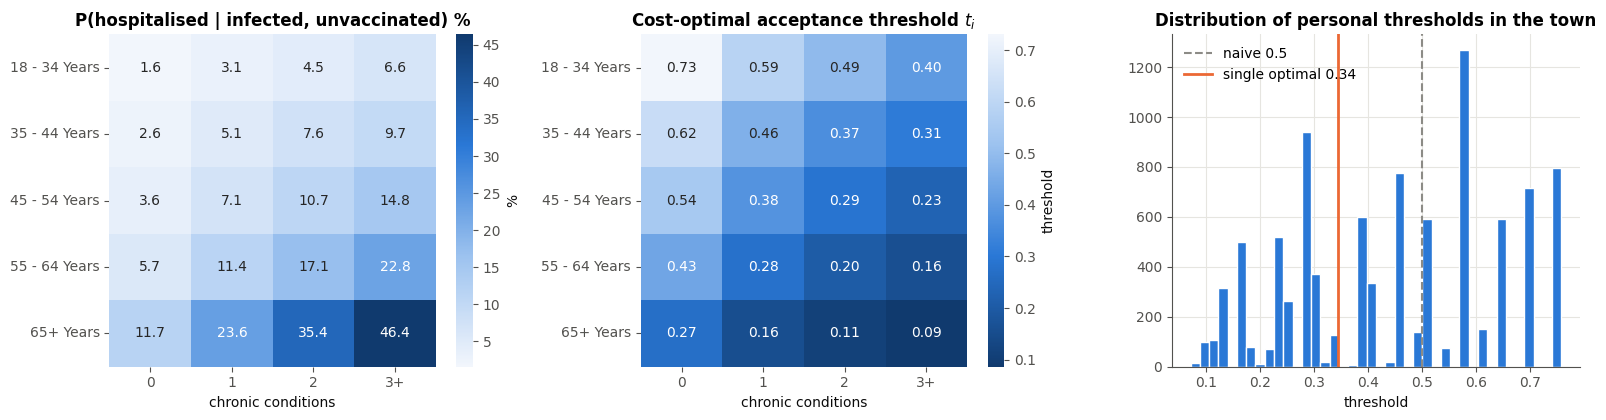

In [4]:
# ---- How does the risk model look across the town? ----
town_view = TOWN.assign(p_hosp=MAIN.p_unvacc(TOWN), threshold=MAIN.personal_threshold(TOWN),
                        chronic=TOWN['number_chronic_med_conditions'].clip(upper=3).astype(str).replace('3', '3+'))
risk_table = town_view.pivot_table(index='age_group', columns='chronic', values='p_hosp', aggfunc='mean').reindex(AGE_ORDER)
thr_table = town_view.pivot_table(index='age_group', columns='chronic', values='threshold', aggfunc='mean').reindex(AGE_ORDER)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sns.heatmap(risk_table * 100, annot=True, fmt='.1f', cmap=SEQ_CMAP, ax=axes[0], cbar_kws={'label': '%'})
axes[0].set_title('P(hospitalised | infected, unvaccinated) %'); axes[0].set_xlabel('chronic conditions'); axes[0].set_ylabel('')
sns.heatmap(thr_table, annot=True, fmt='.2f', cmap=SEQ_CMAP.reversed(), ax=axes[1], cbar_kws={'label': 'threshold'})
axes[1].set_title('Cost-optimal acceptance threshold $t_i$'); axes[1].set_xlabel('chronic conditions'); axes[1].set_ylabel('')
axes[2].hist(town_view['threshold'], bins=40, color=BLUE, edgecolor='white')
axes[2].axvline(0.5, color=GREY, ls='--', lw=1.5, label='naive 0.5')
axes[2].axvline(MAIN.global_threshold(), color=ORANGE, lw=2, label=f'single optimal {MAIN.global_threshold():.2f}')
axes[2].set_title('Distribution of personal thresholds in the town'); axes[2].set_xlabel('threshold'); axes[2].legend()
plt.tight_layout(); savefig('02_risk_model'); plt.show()

**Reading the figure.** Under the main scenario the town's average unvaccinated hospitalisation risk is roughly 8 %, giving a
single optimal threshold around 0.35 (lower than 0.5 because a missed willing person is expensive). The personal thresholds
spread from ≈0.75 (young, healthy women) down to ≈0.1 (65+ with several chronic conditions). This metric will be our
**main evaluation measure**, reported as **$ per resident** (so that folds and data sets of different sizes are comparable) and as the
**total for the test town** (4 749 residents).

In [5]:
# ---- Reference points on the training data: what do trivial strategies cost? ----
y_all = train_raw[TARGET].to_numpy()
refs = {
    'Send to nobody (pay cash to all willing)': np.zeros_like(y_all),
    'Send to everybody': np.ones_like(y_all),
    'Send only if doctor recommended': train_raw['doctor_recc_covid'].to_numpy(),
    'Perfect knowledge (oracle)': y_all,
}
pd.DataFrame({k: {s.name: round(cost_per_person(y_all, v, train_raw, s), 1) for s in SCENARIOS}
              for k, v in refs.items()}).T.rename_axis('$ per resident (training data)')

,A: age+conditions+sex (main),B: age only,C: flat town average,D: mild (Omicron-like),"E: severe, high VE"
$ per resident (training data),,,,,
Send to nobody (pay cash to all willing),3809.3,3793.3,3850.8,2149.7,5469.0
Send to everybody,3743.5,3793.9,3927.3,2716.6,4675.3
Send only if doctor recommended,3333.9,3395.4,3499.6,2014.4,4602.3
Perfect knowledge (oracle),2733.6,2784.0,2917.5,1706.8,3665.5


The gap between *send to nobody* and the *oracle* is the money a perfect model could save. Note that **"send to everybody"
is already better than "send to nobody"** under the main scenario – vaccinating willing elderly people is very valuable – so a useful model must beat
*both* trivial strategies. All later results are compared with these reference points.

**Next:** notebook 02 explores the data.